# 07b · Template check: is the model reading complaints or recognising templates? BankSight

**Why this notebook exists.** Notebook 07 showed that many narratives are **templated letters** (legal wording about the FCRA, "section 1681", "605b",
"your expertise is invaluable...") and that some topics are tied to **one company or app** (Cash App, Zelle, Navy Federal). Those topics have very
different relief rates (about 0% for Cash App and Zelle, 45% to 54% for FCRA letters, 18% for ordinary stories).
A text model could score well simply by *recognising the template or the company*, without understanding the complaint.

**Three questions**
1. Does the champion model (B4) still beat the product-only baseline **inside** each topic, including the big "ordinary stories" topic?
2. When did the templated topics appear? (campaigns come in waves, which makes future data look different)
3. How much of the data is repeated wording, and does the model do as well on non-repeated narratives?

**What this does:** loads the libraries.

In [1]:
from pathlib import Path

import duckdb
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from IPython.display import display
from sklearn.metrics import average_precision_score, roc_auc_score

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 100)

**What this does:** sets file locations and two settings. A group needs at least 300 complaints before we compute a ranking score for it
(smaller groups give unstable scores). A narrative counts as "repeated wording" if its first 150 characters appear at least 5 times in the data.

In [2]:
ROOT = Path("..") if Path.cwd().name == "notebooks" else Path(".")
WAREHOUSE = ROOT / "data" / "warehouse" / "banksight.duckdb"
MODEL_DIR = ROOT / "models"
REPORT_DIR = ROOT / "reports" / "topics"
FIG_DIR = ROOT / "reports" / "figures"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
assert (MODEL_DIR / "04_champion_bundle.joblib").exists(), "Run notebook 04 first."
assert (MODEL_DIR / "07_topic_model.joblib").exists(), "Run notebook 07 first."

MIN_N_AUC = 300
OPENING_CHARS = 150
MIN_REPEATS = 5

## 0. Load narratives and the two saved models

**What this does:** reads train and validation complaints (test is excluded in the SQL) and cleans the text the same way as notebooks 03, 04 and 07.

In [3]:
con = duckdb.connect(str(WAREHOUSE), read_only=True)
df = con.sql("""
    SELECT l.complaint_id, l.date_received, l.product_group, l.got_relief, l.split, r.issue, r.narrative
    FROM features.complaint_labels l
    JOIN raw.cfpb_complaints r USING (complaint_id)
    WHERE l.target_eligible
      AND l.split IN ('train', 'validation')
      AND r.narrative IS NOT NULL AND length(trim(r.narrative)) > 0
""").df()
con.close()

df["issue"] = df["issue"].fillna("Unknown").astype(str)
df["date_received"] = pd.to_datetime(df["date_received"])
df["month"] = df["date_received"].dt.to_period("M").astype(str)
df = df.sort_values("date_received", kind="stable").reset_index(drop=True)

clean_text = df["narrative"].str.replace(r"\{\$[\d,\.]+\}|\$\s?[\d,]+(?:\.\d+)?", " amtmask ", regex=True)
clean_text = clean_text.str.replace(r"\bXX/XX/(?:XXXX|\d{2,4})\b|\bXX/\d{2}/\d{2,4}\b", " datemask ", regex=True)
clean_text = clean_text.str.replace(r"\bX{2,}\b", " xmask ", regex=True)
df["text"] = clean_text.str.replace(r"\s+", " ", regex=True).str.strip()
is_valid = (df["split"] == "validation").to_numpy()
print(f"rows: {len(df):,} | validation rows: {is_valid.sum():,}")

rows: 122,314 | validation rows: 18,537


**What this does:** opens the champion model from notebook 04 (text vectoriser, product/issue encoder and logistic model) and the topic model from notebook 07.

In [4]:
bundle = joblib.load(MODEL_DIR / "04_champion_bundle.joblib")
tfidf = bundle["tfidf"]
ohe = bundle["ohe"]
b4_model = bundle["b4_model"]

topic_bundle = joblib.load(MODEL_DIR / "07_topic_model.joblib")
topic_vectorizer = topic_bundle["vectorizer"]
nmf = topic_bundle["nmf"]
topic_labels = topic_bundle["topic_labels"]
print("topics in the saved model:", len(topic_labels))

topics in the saved model: 12


**What this does:** gives every complaint its main topic, using the saved topic model (the same way notebook 07 did).

In [5]:
W = nmf.transform(topic_vectorizer.transform(df["text"]))
df["topic"] = np.where(W.sum(axis=1) > 0, W.argmax(axis=1), -1)
df["topic_label"] = df["topic"].map(topic_labels).fillna("none")
print(df["topic_label"].value_counts().to_string())

topic_label
T2: general bank/card/money stories            59712
T5: credit report errors and identity theft    26564
T8: debt collection validation                 12667
T0: Cash App complaints                         6427
T7: late-payment bureau dispute letters         3509
T1: Zelle complaints                            3368
T3: FCRA section 1681 letters                   3261
T4: Navy Federal overdraft fees                 2233
T6: FCRA 605b block letters                     1567
T10: unauthorized transactions                  1301
T11: inaccurate-account correction letters       964
T9: templated review-and-feedback letters        729
none                                              12


**What this does:** scores the **validation** complaints with the champion model (B4), and with the simple baseline "relief rate of the complaint's
product, measured on train" (B1). Train rows are not scored, because the model has already seen them.

In [6]:
valid = df[is_valid].copy()
X_valid = sp.hstack([tfidf.transform(valid["text"]), ohe.transform(valid[["product_group", "issue"]])]).tocsr()
valid["p_b4"] = b4_model.predict_proba(X_valid)[:, 1]

product_rate_train = df[~is_valid].groupby("product_group")["got_relief"].mean()
valid["p_b1"] = valid["product_group"].map(product_rate_train).fillna(df[~is_valid]["got_relief"].mean())

print("overall validation PR-AUC  B1:", round(average_precision_score(valid["got_relief"], valid["p_b1"]), 4),
      "| B4:", round(average_precision_score(valid["got_relief"], valid["p_b4"]), 4))

overall validation PR-AUC  B1: 0.3451 | B4: 0.4275


## 1. Does B4 beat the product-only baseline inside each topic?
If B4 is only recognising templates, its advantage should shrink or vanish **within** a topic, because the template is the same for everyone there.

**What this does:** for each topic with enough validation complaints, shows the relief rate and the ranking score (ROC-AUC) of B1 and of B4, and the
gain B4 adds. A positive gain inside a topic means the model separates complaints *within* that topic.

In [7]:
rows = []
for topic_name in valid["topic_label"].value_counts().index:
    part = valid[valid["topic_label"] == topic_name]
    y_part = part["got_relief"].to_numpy()
    if len(part) < MIN_N_AUC or y_part.min() == y_part.max():
        continue
    rows.append({
        "topic": topic_name,
        "validation_complaints": len(part),
        "relief_rate": y_part.mean(),
        "roc_auc_B1": roc_auc_score(y_part, part["p_b1"]),
        "roc_auc_B4": roc_auc_score(y_part, part["p_b4"]),
        "pr_auc_B1": average_precision_score(y_part, part["p_b1"]),
        "pr_auc_B4": average_precision_score(y_part, part["p_b4"]),
    })

by_topic = pd.DataFrame(rows)
by_topic["roc_auc_gain"] = by_topic["roc_auc_B4"] - by_topic["roc_auc_B1"]
by_topic["pr_auc_gain"] = by_topic["pr_auc_B4"] - by_topic["pr_auc_B1"]
display(by_topic)
by_topic.to_csv(REPORT_DIR / "07b_model_by_topic_validation.csv", index=False)

,topic,validation_complaints,relief_rate,roc_auc_B1,roc_auc_B4,pr_auc_B1,pr_auc_B4,roc_auc_gain,pr_auc_gain
0,T2: general bank/card/money stories,8883,0.156929,0.664589,0.759942,0.235218,0.367778,0.095353,0.132561
1,T5: credit report errors and identity theft,5627,0.340146,0.596558,0.652705,0.392661,0.460659,0.056147,0.067999
2,T8: debt collection validation,2403,0.201415,0.608159,0.736867,0.251867,0.407595,0.128707,0.155727
3,T7: late-payment bureau dispute letters,383,0.381201,0.660988,0.702170,0.483849,0.560161,0.041183,0.076312


**What this does:** looks at the biggest topic on its own. In notebook 07 that was the topic of ordinary personal stories (bank, card, money, told,
called...). This is the fairest test of whether the model understands complaints. The cell prints the topic's words so you can confirm it.

In [8]:
organic_topic = df[df["split"] == "train"]["topic"].value_counts().idxmax()
organic_label = topic_labels[organic_topic]
print("largest topic (assumed to be ordinary stories):", organic_label)

organic = valid[valid["topic"] == organic_topic]
y_org = organic["got_relief"].to_numpy()
print(f"validation complaints in it: {len(organic):,} | relief rate {y_org.mean():.3f}")
print("PR-AUC  B1:", round(average_precision_score(y_org, organic["p_b1"]), 4),
      "| B4:", round(average_precision_score(y_org, organic["p_b4"]), 4))
print("ROC-AUC B1:", round(roc_auc_score(y_org, organic["p_b1"]), 4),
      "| B4:", round(roc_auc_score(y_org, organic["p_b4"]), 4))

largest topic (assumed to be ordinary stories): T2: general bank/card/money stories
validation complaints in it: 8,883 | relief rate 0.157
PR-AUC  B1: 0.2352 | B4: 0.3678
ROC-AUC B1: 0.6646 | B4: 0.7599


## 2. When did the templated topics appear?
Campaign-style templates arrive in **waves**. A wave that is common in training and gone in production (or the reverse) is a classic cause of a model
quietly getting worse.

**What this does:** computes each topic's share of complaints in every month.

In [9]:
monthly_share = pd.crosstab(df["month"], df["topic_label"], normalize="index")
monthly_share.to_csv(REPORT_DIR / "07b_topic_share_by_month.csv")
display(monthly_share.round(3).tail(12))

topic_label,T0: Cash App complaints,T10: unauthorized transactions,T11: inaccurate-account correction letters,T1: Zelle complaints,T2: general bank/card/money stories,T3: FCRA section 1681 letters,T4: Navy Federal overdraft fees,T5: credit report errors and identity theft,T6: FCRA 605b block letters,T7: late-payment bureau dispute letters,T8: debt collection validation,T9: templated review-and-feedback letters,none
month,,,,,,,,,,,,,
2024-11,0.001,0.007,0.011,0.000,0.495,0.030,0.030,0.248,0.016,0.024,0.127,0.012,0.000
2024-12,0.001,0.008,0.013,0.001,0.514,0.034,0.010,0.257,0.015,0.024,0.116,0.005,0.000
2025-01,0.344,0.005,0.004,0.181,0.216,0.009,0.078,0.095,0.002,0.008,0.044,0.014,0.000
2025-02,0.102,0.008,0.006,0.053,0.423,0.020,0.023,0.223,0.012,0.018,0.102,0.010,0.000
2025-03,0.032,0.015,0.006,0.005,0.437,0.022,0.007,0.278,0.025,0.017,0.150,0.007,0.000
2025-04,0.015,0.010,0.007,0.001,0.450,0.017,0.009,0.287,0.024,0.018,0.152,0.008,0.000
2025-05,0.019,0.008,0.006,0.000,0.460,0.016,0.007,0.305,0.017,0.011,0.143,0.007,0.000
2025-06,0.010,0.011,0.006,0.002,0.468,0.015,0.007,0.324,0.012,0.014,0.129,0.003,0.000
2025-07,0.008,0.012,0.006,0.001,0.476,0.012,0.006,0.327,0.006,0.011,0.126,0.008,0.001


**What this does:** draws the six topics whose monthly share moves the most (biggest gap between their highest and lowest month).

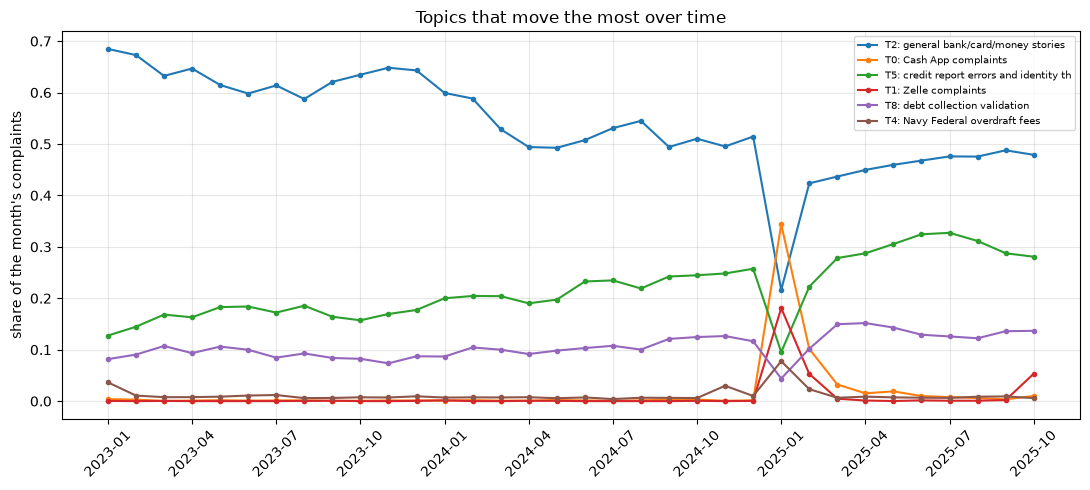

In [10]:
movement = monthly_share.max() - monthly_share.min()
movers = movement.sort_values(ascending=False).head(6).index

plt.figure(figsize=(11, 5))
for topic_name in movers:
    plt.plot(monthly_share.index, monthly_share[topic_name], marker="o", markersize=3, label=topic_name[:40])
plt.xticks(range(0, len(monthly_share.index), 3), monthly_share.index[::3], rotation=45)
plt.ylabel("share of the month's complaints")
plt.title("Topics that move the most over time")
plt.legend(fontsize=7)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "07b_topic_waves.png", dpi=140)
plt.show()

## 3. How much wording is repeated, and does it matter?

**What this does:** takes the first 150 characters of every cleaned narrative as a "fingerprint" and counts how often each fingerprint appears.
A narrative whose opening appears 5 or more times is flagged as **repeated wording** (a template or a copied letter).

In [11]:
df["opening"] = df["text"].str.slice(0, OPENING_CHARS)
opening_counts = df["opening"].map(df["opening"].value_counts())
df["repeated_wording"] = opening_counts >= MIN_REPEATS
print(f"share of narratives with repeated wording: {df['repeated_wording'].mean():.1%}")

share of narratives with repeated wording: 19.6%


**What this does:** shows, for each topic, what share of its complaints has repeated wording. High shares confirm which topics are template-driven.

In [12]:
repeat_by_topic = df.groupby("topic_label").agg(complaints=("repeated_wording", "size"), repeated_share=("repeated_wording", "mean"))
repeat_by_topic = repeat_by_topic.sort_values("repeated_share", ascending=False)
display(repeat_by_topic)
repeat_by_topic.to_csv(REPORT_DIR / "07b_repeated_wording_by_topic.csv")

,complaints,repeated_share
topic_label,,
T6: FCRA 605b block letters,1567,0.861519
T9: templated review-and-feedback letters,729,0.766804
T0: Cash App complaints,6427,0.727244
T1: Zelle complaints,3368,0.680819
T10: unauthorized transactions,1301,0.632590
T11: inaccurate-account correction letters,964,0.546680
T7: late-payment bureau dispute letters,3509,0.508122
T3: FCRA section 1681 letters,3261,0.480527
T4: Navy Federal overdraft fees,2233,0.362293


**What this does:** in the train period, compares the relief rate of repeated-wording narratives with the rest.

In [13]:
train_part = df[df["split"] == "train"]
relief_by_repeat = train_part.groupby("repeated_wording")["got_relief"].agg(complaints="size", relief_rate="mean")
display(relief_by_repeat)

,complaints,relief_rate
repeated_wording,,
False,82930,0.211576
True,20847,0.338370


**What this does:** compares the champion model with the product-only baseline on validation complaints **with** and **without** repeated wording.
If B4's advantage is much smaller on non-repeated narratives, part of its lift comes from recognising templates.

In [14]:
valid["repeated_wording"] = df.loc[is_valid, "repeated_wording"].to_numpy()

rows = []
for flag_value, name in ((False, "non-repeated wording"), (True, "repeated wording")):
    part = valid[valid["repeated_wording"] == flag_value]
    y_part = part["got_relief"].to_numpy()
    if len(part) < MIN_N_AUC or y_part.min() == y_part.max():
        continue
    rows.append({
        "group": name,
        "validation_complaints": len(part),
        "relief_rate": y_part.mean(),
        "pr_auc_B1": average_precision_score(y_part, part["p_b1"]),
        "pr_auc_B4": average_precision_score(y_part, part["p_b4"]),
        "roc_auc_B1": roc_auc_score(y_part, part["p_b1"]),
        "roc_auc_B4": roc_auc_score(y_part, part["p_b4"]),
    })

repeat_perf = pd.DataFrame(rows)
repeat_perf["pr_auc_gain"] = repeat_perf["pr_auc_B4"] - repeat_perf["pr_auc_B1"]
repeat_perf["roc_auc_gain"] = repeat_perf["roc_auc_B4"] - repeat_perf["roc_auc_B1"]
display(repeat_perf)
repeat_perf.to_csv(REPORT_DIR / "07b_model_by_repeated_wording.csv", index=False)

,group,validation_complaints,relief_rate,pr_auc_B1,pr_auc_B4,roc_auc_B1,roc_auc_B4,pr_auc_gain,roc_auc_gain
0,non-repeated wording,15352,0.199909,0.308285,0.423944,0.686538,0.762655,0.115660,0.076117
1,repeated wording,3185,0.362009,0.407326,0.440739,0.584136,0.603319,0.033414,0.019184


## 4. Plain-English reading of the results
Fill in your own conclusions after reading the tables:
* If B4 still clearly beats B1 **inside the ordinary-stories topic** and on **non-repeated** narratives, the model learned real content signal.
* If its gain nearly disappears there, then most of the lift is template and company recognition. That is still a useful model for *current* traffic,
  but it needs frequent monitoring and retraining, and the model card must say so.
* Either way, repeated wording means complaints are **not independent** (many near-copies), so every confidence interval in notebooks 03 to 05 is
  somewhat optimistic.

## How to explain this in an interview
> "Topic modelling showed that a large part of the narratives are templated letters and company-specific complaints with very different relief rates.
> Because a text model can exploit that, I tested the champion inside each topic and on non-repeated narratives, and I tracked when the template
> waves appear. That told me how much of the lift is real language understanding and what to monitor in production."